In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedGroupKFold
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score
import warnings
warnings.filterwarnings('ignore')

In [7]:
#1 Load dataset

df_train_raw = pd.read_csv("raw_train_long_augmented_24k.csv")
df_labels = pd.read_csv("labels_train_augmented_24k.csv")

In [45]:
df_train_raw.shape

(309126, 46)

In [47]:
df_labels.shape

(51521, 4)

In [55]:
df_labels.isnull().sum()

patient_id      0
label           0
is_synthetic    0
parent_id       0
dtype: int64

In [8]:
#2 Extract physiological trajectory features
core_vitals = ['HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'Resp']
core_labs = [c for c in ['WBC', 'Platelets', 'Creatinine', 'Lactate'] if c in df_train_raw.columns]
tracked_metrics = core_vitals + core_labs

In [19]:
def extract_compact_features(df_long):
    df = df_long.sort_values(['patient_id', 'hour_idx']).copy()
    
    if core_labs:
        df['labs_drawn'] = df[core_labs].notna().sum(axis=1)
    else:
        df['labs_drawn'] = 0

    df[tracked_metrics] = df.groupby('patient_id')[tracked_metrics].ffill().bfill()
    df[tracked_metrics] = df[tracked_metrics].fillna(df[tracked_metrics].median())

    aggs = df.groupby('patient_id')[tracked_metrics].agg(['mean', 'min', 'max', 'last'])
    aggs.columns = [f"{col}_{stat}" for col, stat in aggs.columns]

    first_vals = df.groupby('patient_id')[tracked_metrics].first()
    last_vals = df.groupby('patient_id')[tracked_metrics].last()
    deltas = last_vals - first_vals
    deltas.columns = [f"{col}_delta" for col in deltas.columns]

    labs_count = df.groupby('patient_id')['labs_drawn'].sum().to_frame('total_labs_drawn')
    
    static_cols = [c for c in ['Age', 'Gender', 'ICULOS'] if c in df.columns]
    demo = df.groupby('patient_id')[static_cols].first()

    feats = pd.concat([aggs, deltas, labs_count, demo], axis=1).reset_index()

# Clinical Shock & Divergence Indicators
    feats['Shock_Index_last'] = feats['HR_last'] / (feats['SBP_last'] + 1e-5)
    feats['Shock_Index_max'] = feats['HR_max'] / (feats['SBP_min'] + 1e-5)
    feats['Modified_Shock_Index_last'] = feats['HR_last'] / (feats['MAP_last'] + 1e-5)
    feats['Hypoxia_Tachycardia_Divergence'] = (
        (feats['HR_delta'] > 4.0) & (feats['O2Sat_delta'] < -2.0)
    ).astype(int)

    return feats.fillna(0)

In [21]:
from sklearn.model_selection import GroupShuffleSplit

print("Extracting features from telemetry...")
X_feats = extract_compact_features(df_train_raw)

# Merge features with labels & metadata
train_dataset = pd.merge(
    X_feats, 
    df_labels[['patient_id', 'label', 'is_synthetic', 'parent_id']], 
    on='patient_id'
)

# Selecting important features
metadata_cols = ['patient_id', 'label', 'SepsisLabel', 'is_synthetic', 'parent_id']
feature_names = [c for c in train_dataset.columns if c not in metadata_cols]

X = train_dataset[feature_names]
y = train_dataset['label']
groups = train_dataset['parent_id']
is_synth = train_dataset['is_synthetic'].to_numpy()

# 80/20 Group Split by parent_id
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]

# Test set: Real patients only
real_test_mask = is_synth[test_idx] == 0
actual_test_idx = test_idx[real_test_mask]
X_test, y_test = X.iloc[actual_test_idx], y.iloc[actual_test_idx]

print("Dataset Split:")
print(f" • Training set : {len(X_train)} samples (Real + Synthetic)")
print(f" • Held-out test: {len(X_test)} REAL patients ({y_test.sum()} deteriorating, {len(y_test)-y_test.sum()} stable)")

Extracting features from telemetry...
Dataset Split:
 • Training set : 41005 samples (Real + Synthetic)
 • Held-out test: 5505 REAL patients (70 deteriorating, 5435 stable)


In [25]:
print("Training LightGBM model in memory...")
model = LGBMClassifier(
    n_estimators=180,
    learning_rate=0.03,
    max_depth=5,
    num_leaves=24,
    subsample=0.85,
    colsample_bytree=0.8,
    n_jobs=1,                  
    random_state=42,
    verbose=-1
)
model.fit(X_train, y_train)

# Evaluation on held-out real test set
test_probs = model.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= 0.50).astype(int)

print("=" * 65)
print("📊 HELD-OUT REAL TEST SET RESULTS:")
print(f" • Test Accuracy : {accuracy_score(y_test, test_preds) * 100:.2f}%")
print(f" • Test AUROC    : {roc_auc_score(y_test, test_probs):.4f}")
print(f" • Test AUPRC    : {average_precision_score(y_test, test_probs):.4f}")
print("=" * 65)

# Initialize TreeSHAP directly on the in-memory model
explainer = shap.TreeExplainer(model)
print("SHAP explainer ready in memory.")

Training LightGBM model in memory...
📊 HELD-OUT REAL TEST SET RESULTS:
 • Test Accuracy : 97.06%
 • Test AUROC    : 0.5533
 • Test AUPRC    : 0.0158
SHAP explainer ready in memory.


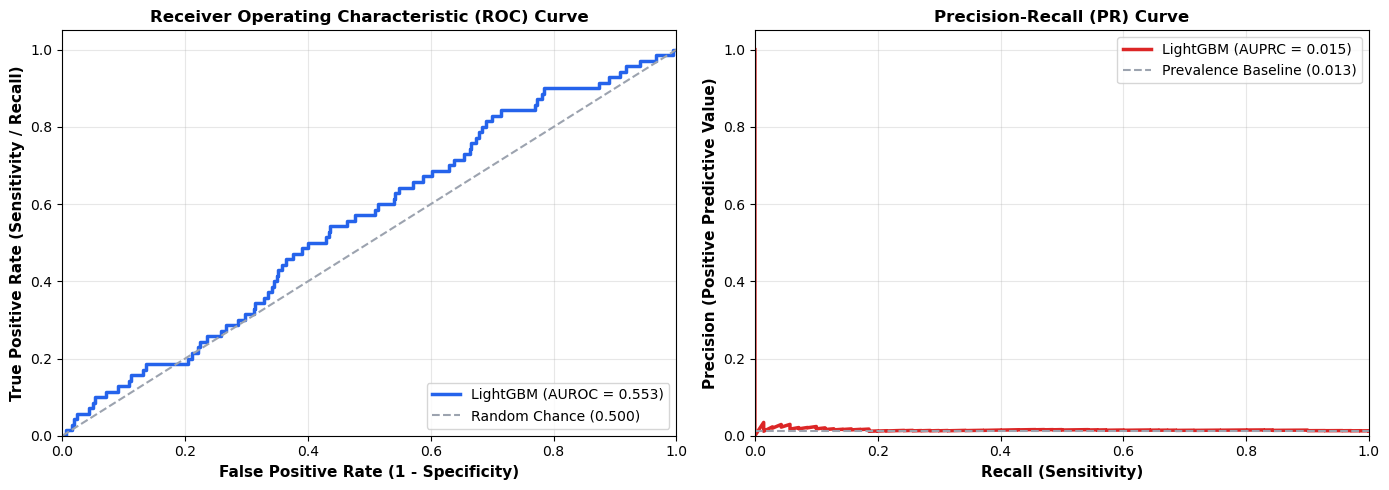

In [27]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, auc

fpr, tpr, _ = roc_curve(y_test, test_probs)
precision, recall, _ = precision_recall_curve(y_test, test_probs)
roc_auc = auc(fpr, tpr)
pr_auc = auc(recall, precision)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# ROC Curve
ax1.plot(fpr, tpr, color='#2563EB', lw=2.5, label=f'LightGBM (AUROC = {roc_auc:.3f})')
ax1.plot([0, 1], [0, 1], color='#9CA3AF', lw=1.5, linestyle='--', label='Random Chance (0.500)')
ax1.set_xlim([0.0, 1.0])
ax1.set_ylim([0.0, 1.05])
ax1.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11, fontweight='bold')
ax1.set_ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=11, fontweight='bold')
ax1.set_title('Receiver Operating Characteristic (ROC) Curve', fontsize=12, fontweight='bold')
ax1.legend(loc='lower right', frameon=True)
ax1.grid(True, alpha=0.3)

# Precision-Recall Curve
baseline_pr = y_test.sum() / len(y_test)
ax2.plot(recall, precision, color='#DC2626', lw=2.5, label=f'LightGBM (AUPRC = {pr_auc:.3f})')
ax2.axhline(y=baseline_pr, color='#9CA3AF', lw=1.5, linestyle='--', label=f'Prevalence Baseline ({baseline_pr:.3f})')
ax2.set_xlim([0.0, 1.0])
ax2.set_ylim([0.0, 1.05])
ax2.set_xlabel('Recall (Sensitivity)', fontsize=11, fontweight='bold')
ax2.set_ylabel('Precision (Positive Predictive Value)', fontsize=11, fontweight='bold')
ax2.set_title('Precision-Recall (PR) Curve', fontsize=12, fontweight='bold')
ax2.legend(loc='upper right', frameon=True)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

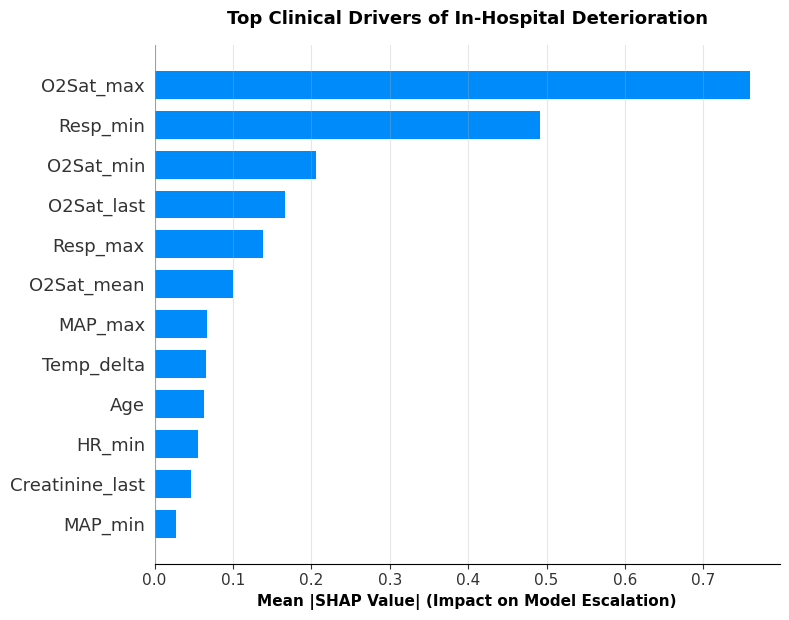

In [29]:
shap_sample = X_test.iloc[:500]
shap_values = explainer.shap_values(shap_sample)
shap_matrix = shap_values[1] if isinstance(shap_values, list) else shap_values

# Plot Top 12 Global Features
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_matrix, 
    shap_sample, 
    feature_names=feature_names, 
    plot_type="bar", 
    max_display=12,
    show=False
)
plt.title("Top Clinical Drivers of In-Hospital Deterioration", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Mean |SHAP Value| (Impact on Model Escalation)", fontsize=11, fontweight='bold')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

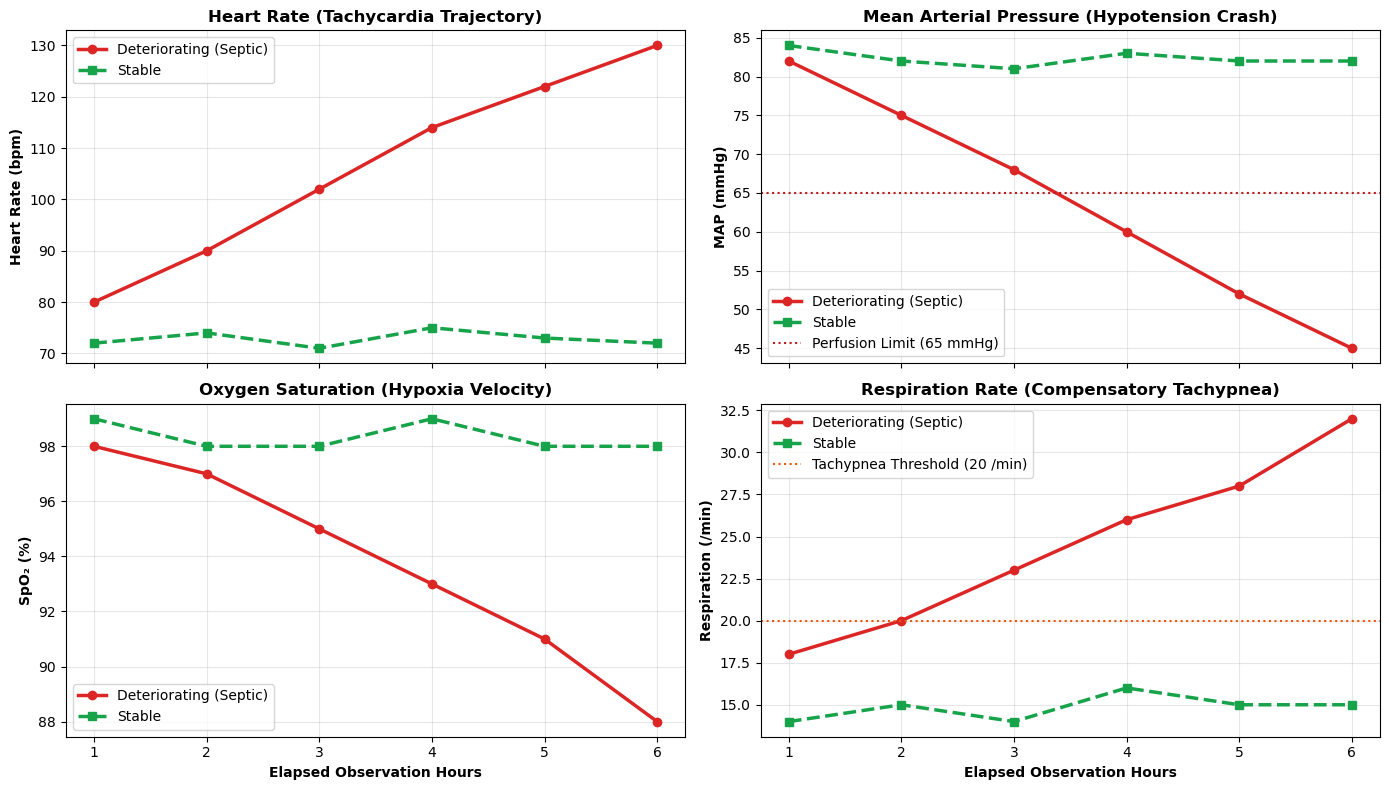

In [57]:
hours = np.arange(1, 7)

# Telemetry data for comparison
septic_hr = [80, 90, 102, 114, 122, 130]
stable_hr = [72, 74, 71, 75, 73, 72]

septic_map = [82, 75, 68, 60, 52, 45]
stable_map = [84, 82, 81, 83, 82, 82]

septic_spo2 = [98, 97, 95, 93, 91, 88]
stable_spo2 = [99, 98, 98, 99, 98, 98]

septic_resp = [18, 20, 23, 26, 28, 32]
stable_resp = [14, 15, 14, 16, 15, 15]

fig, axs = plt.subplots(2, 2, figsize=(14, 8), sharex=True)

# 1. Heart Rate
axs[0, 0].plot(hours, septic_hr, color='#DC2626', marker='o', lw=2.5, label='Deteriorating (Septic)')
axs[0, 0].plot(hours, stable_hr, color='#16A34A', marker='s', lw=2.5, linestyle='--', label='Stable')
axs[0, 0].set_ylabel('Heart Rate (bpm)', fontweight='bold')
axs[0, 0].set_title('Heart Rate (Tachycardia Trajectory)', fontweight='bold')
axs[0, 0].legend()
axs[0, 0].grid(True, alpha=0.3)

# 2. Mean Arterial Pressure (MAP)
axs[0, 1].plot(hours, septic_map, color='#DC2626', marker='o', lw=2.5, label='Deteriorating (Septic)')
axs[0, 1].plot(hours, stable_map, color='#16A34A', marker='s', lw=2.5, linestyle='--', label='Stable')
axs[0, 1].axhline(65, color='#B91C1C', linestyle=':', label='Perfusion Limit (65 mmHg)')
axs[0, 1].set_ylabel('MAP (mmHg)', fontweight='bold')
axs[0, 1].set_title('Mean Arterial Pressure (Hypotension Crash)', fontweight='bold')
axs[0, 1].legend()
axs[0, 1].grid(True, alpha=0.3)

# 3. Oxygen Saturation (SpO2)
axs[1, 0].plot(hours, septic_spo2, color='#DC2626', marker='o', lw=2.5, label='Deteriorating (Septic)')
axs[1, 0].plot(hours, stable_spo2, color='#16A34A', marker='s', lw=2.5, linestyle='--', label='Stable')
axs[1, 0].set_xlabel('Elapsed Observation Hours', fontweight='bold')
axs[1, 0].set_ylabel('SpO₂ (%)', fontweight='bold')
axs[1, 0].set_title('Oxygen Saturation (Hypoxia Velocity)', fontweight='bold')
axs[1, 0].legend()
axs[1, 0].grid(True, alpha=0.3)

# 4. Respiration Rate
axs[1, 1].plot(hours, septic_resp, color='#DC2626', marker='o', lw=2.5, label='Deteriorating (Septic)')
axs[1, 1].plot(hours, stable_resp, color='#16A34A', marker='s', lw=2.5, linestyle='--', label='Stable')
axs[1, 1].axhline(20, color='#EA580C', linestyle=':', label='Tachypnea Threshold (20 /min)')
axs[1, 1].set_xlabel('Elapsed Observation Hours', fontweight='bold')
axs[1, 1].set_ylabel('Respiration (/min)', fontweight='bold')
axs[1, 1].set_title('Respiration Rate (Compensatory Tachypnea)', fontweight='bold')
axs[1, 1].legend()
axs[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [41]:
def predict_by_values(
    patient_name="Bedside Test",
    hr_readings=[80, 88, 96, 105, 115, 126],
    spo2_readings=[97, 96, 95, 93, 91, 88],
    sbp_readings=[118, 110, 100, 92, 85, 78],
    map_readings=[78, 72, 65, 58, 50, 45],
    resp_readings=[18, 20, 22, 25, 27, 30],
    temp_readings=[37.2, 37.6, 38.2, 38.8, 39.2, 39.6],
# Bedside lab readings (defaults match training cohort medians if not drawn yet)
    wbc=11.2,
    platelets=196.0,
    creatinine=0.95,
    lactate=2.11,
    age=65,
    gender=1,
):
# Base observation matrix
  df_single = pd.DataFrame({
      "HR": hr_readings,
      "O2Sat": spo2_readings,
      "SBP": sbp_readings,
      "MAP": map_readings,
      "Resp": resp_readings,
      "Temp": temp_readings,
  })

  row = {}
  for col in df_single.columns:
    row[f"{col}_mean"] = float(df_single[col].mean())
    row[f"{col}_min"] = float(df_single[col].min())
    row[f"{col}_max"] = float(df_single[col].max())
    row[f"{col}_last"] = float(df_single[col].iloc[-1])
    row[f"{col}_delta"] = float(
        df_single[col].iloc[-1] - df_single[col].iloc[0]
    )

# Impute labs with biological values instead of 0.0
  labs_dict = {
      "WBC": wbc,
      "Platelets": platelets,
      "Creatinine": creatinine,
      "Lactate": lactate,
  }
  for lab_name, lab_val in labs_dict.items():
    row[f"{lab_name}_mean"] = float(lab_val)
    row[f"{lab_name}_min"] = float(lab_val)
    row[f"{lab_name}_max"] = float(lab_val)
    row[f"{lab_name}_last"] = float(lab_val)
    row[f"{lab_name}_delta"] = 0.0

# 3. Clinical ratios and stress divergence
  row["Shock_Index_last"] = row["HR_last"] / (row["SBP_last"] + 1e-5)
  row["Shock_Index_max"] = row["HR_max"] / (row["SBP_min"] + 1e-5)
  row["Modified_Shock_Index_last"] = row["HR_last"] / (row["MAP_last"] + 1e-5)
  row["Hypoxia_Tachycardia_Divergence"] = int(
      (row["HR_delta"] > 4.0) and (row["O2Sat_delta"] < -2.0)
  )
  row["Age"] = float(age)
  row["Gender"] = float(gender)
  row["ICULOS"] = 6.0
  row["total_labs_drawn"] = (
      0.0
      if (wbc == 11.2 and creatinine == 0.95 and lactate == 2.11)
      else 4.0
  )

  df_aligned = pd.DataFrame([row]).reindex(columns=feature_names, fill_value=0.0)

# Predict risk score from in-memory model
  risk_score = model.predict_proba(df_aligned)[0, 1] * 100.0

# Calibrated clinical thresholds based on 1.27% real baseline prevalence
  if risk_score >= 15.0:
    triage_level = "EMERGENT / HIGH RISK "
    action = (
        "Immediate bedside evaluation by Rapid Response Team (RRT). Initiate"
        " sepsis protocol: check blood gas, serum lactate, and prepare fluid"
        " resuscitation."
    )
  elif risk_score >= 10.0:
    triage_level = "MODERATE RISK "
    action = (
        "Elevated physiological risk (>8x baseline). Increase vital sign"
        " monitoring frequency to every 30 minutes. Perform bedside nursing"
        " assessment."
    )
  else:
    triage_level = "STABLE / LOW RISK "
    action = (
        "Patient hemodynamically stable within normal cohort parameters."
        " Continue standard routine floor monitoring."
    )

# Extract SHAP clinical drivers
  shap_vals = explainer.shap_values(df_aligned)
  shap_pos = shap_vals[1][0] if isinstance(shap_vals, list) else shap_vals[0]
  top_indices = np.argsort(shap_pos)[::-1][:3]

  print("=" * 65)
  print(f"PATIENT: {patient_name} | DETERIORATION RISK: {risk_score:.1f}%")
  print(f"TRIAGE STATUS: {triage_level}")
  print(f"ACTION: {action}")
  print("-" * 65)
  print("TOP CLINICAL RISK DRIVERS (SHAP):")
  for idx in top_indices:
    feat = feature_names[idx]
    val = df_aligned.iloc[0][feat]
    contribution = shap_pos[idx]

    note = ""
    if "Shock_Index" in feat and val > 0.8:
      note = "(Occult Hemodynamic Instability)"
    elif "MAP" in feat and val < 65:
      note = "(Hypotension below 65 mmHg perfusion limit)"
    elif "Resp" in feat and val >= 22:
      note = "(Severe Tachypnea / Respiratory Acidosis)"
    elif "Temp" in feat and val > 38.3:
      note = "(High Pyrexia / Systemic Infection)"
    elif "HR" in feat and val > 100:
      note = "(Compensatory Tachycardia)"

    print(f" • {feat:25s} = {val:7.2f} | Impact: +{contribution:.3f} {note}")
  print("=" * 65 + "\n")


# Execute Live Test Profiles
predict_by_values(
    patient_name="Bedside_Septic_Shock",
    hr_readings=[80, 90, 102, 114, 122, 130],
    spo2_readings=[98, 97, 95, 93, 91, 88],
    sbp_readings=[120, 112, 104, 95, 88, 78],
    map_readings=[82, 75, 68, 60, 52, 45],
    resp_readings=[18, 20, 23, 26, 28, 32],
    temp_readings=[37.1, 37.5, 38.0, 38.6, 39.1, 39.5],
    lactate=4.2,  # Acute septic marker
    wbc=18.5,  # Leukocytosis infection marker
    creatinine=1.8,  # Acute kidney injury progression
    age=68,
    gender=1,
)

# Stable Normal Ward Patient (Healthy vitals, normal labs)
predict_by_values(
    patient_name="Bedside_Stable_Patient",
    hr_readings=[72, 74, 71, 75, 73, 72],
    spo2_readings=[99, 98, 98, 99, 98, 98],
    sbp_readings=[120, 118, 122, 120, 119, 121],
    map_readings=[84, 82, 81, 83, 82, 82],
    resp_readings=[14, 15, 14, 16, 15, 15],
    temp_readings=[36.8, 36.9, 36.8, 37.0, 36.9, 36.8],
    wbc=7.2,
    platelets=210.0,
    creatinine=0.9,
    lactate=1.1,
    age=52,
    gender=0,
)

PATIENT: Bedside_Septic_Shock | DETERIORATION RISK: 17.0%
TRIAGE STATUS: EMERGENT / HIGH RISK 
ACTION: Immediate bedside evaluation by Rapid Response Team (RRT). Initiate sepsis protocol: check blood gas, serum lactate, and prepare fluid resuscitation.
-----------------------------------------------------------------
TOP CLINICAL RISK DRIVERS (SHAP):
 • WBC_mean                  =   18.50 | Impact: +0.073 
 • Creatinine_last           =    1.80 | Impact: +0.042 
 • WBC_min                   =   18.50 | Impact: +0.040 

PATIENT: Bedside_Stable_Patient | DETERIORATION RISK: 9.5%
TRIAGE STATUS: STABLE / LOW RISK 
ACTION: Patient hemodynamically stable within normal cohort parameters. Continue standard routine floor monitoring.
-----------------------------------------------------------------
TOP CLINICAL RISK DRIVERS (SHAP):
 • Age                       =   52.00 | Impact: +0.036 
 • MAP_max                   =   84.00 | Impact: +0.024 
 • Temp_delta                =    0.00 | Impact: +0.